In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [2]:
from src.data import load_ecg
from src.features import detect_rpeaks
from src.features import rr_intervals

ecg = load_ecg("a01")
peaks = detect_rpeaks(ecg)

print(len(peaks), "beats found")
print(peaks[:10])

29992 beats found
[ 38 127 211 294 377 465 558 655 750 843]


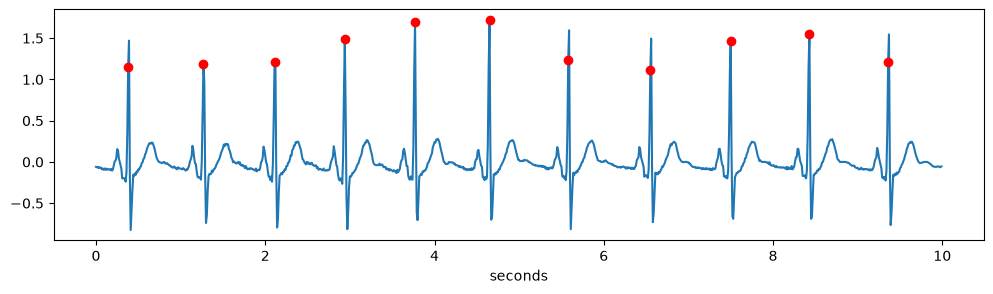

In [3]:
import numpy as np
import matplotlib.pyplot as plt

s, e = 0, 10 * 100          # first 10 seconds (100 samples per second)
p = peaks[(peaks >= s) & (peaks < e)]
plt.figure(figsize=(12, 3))
plt.plot(np.arange(s, e) / 100, ecg[s:e])
plt.plot(p/100, ecg[p], "ro")
plt.xlabel("seconds")
plt.show()

In [4]:
rr = np.diff(peaks)/100 #gap between beats, in seconds
t = peaks[1:]/100 #time of beats

print(len(rr), 'intervals')
print(rr[:10])
print('min:', rr.min(), 'max', rr.max(), 'mean:', rr.mean().round(3))


29991 intervals
[0.89 0.84 0.83 0.83 0.88 0.93 0.97 0.95 0.93 0.93]
min: 0.41 max 1.71 mean: 0.986


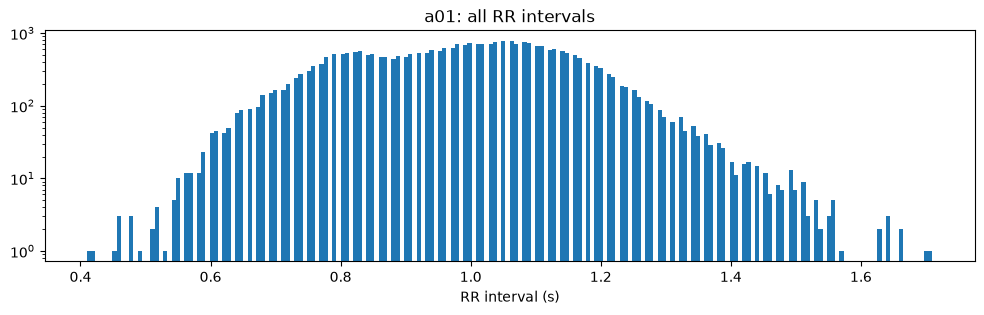

In [5]:
plt.figure(figsize=(12, 3))
plt.hist(rr, bins=200)
plt.yscale("log")              # log scale so rare extreme values are visible
plt.xlabel("RR interval (s)")
plt.title("a01: all RR intervals")
plt.show()

In [6]:
import pandas as pd

rr_df = rr_intervals(peaks)

in_range = (rr_df.rr >= 0.3) & (rr_df.rr <= 2.0)
local_median = rr_df.rr.rolling(11, center=True, min_periods=1).median() #the median of 11 rrs 5-1-5
no_jump = (rr_df.rr - local_median).abs() <= 0.3 * local_median
rr_df["valid"] = in_range & no_jump

print("kept:", rr_df.valid.mean() * 100, "%")
print("removed:", (~rr_df.valid).sum(), "intervals")
rr_df.head()

kept: 99.27311526791371 %
removed: 218 intervals


,t,rr,valid
0,1.27,0.89,True
1,2.11,0.84,True
2,2.94,0.83,True
3,3.77,0.83,True
4,4.65,0.88,True


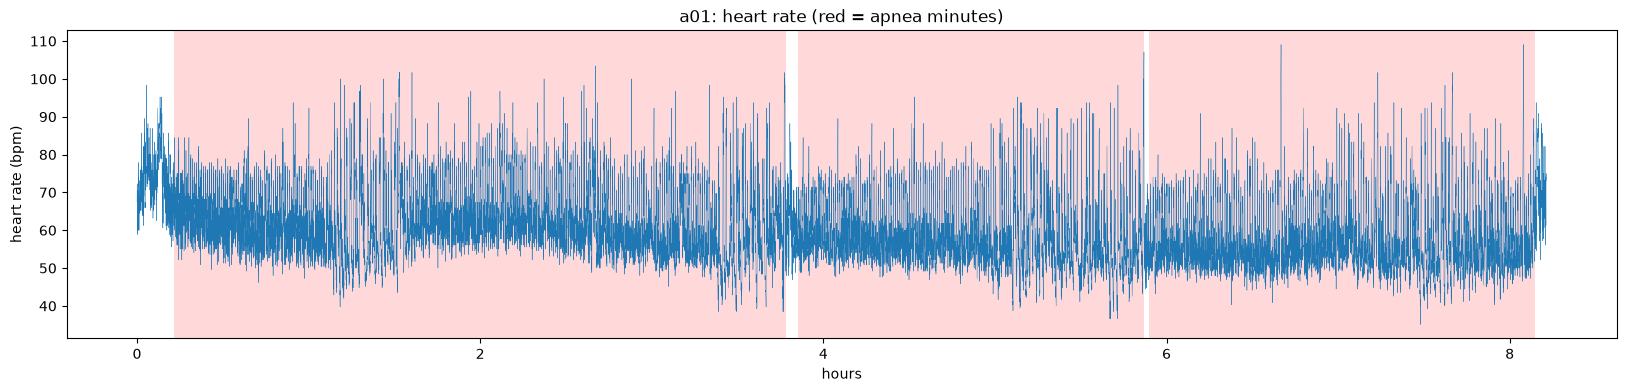

In [7]:
from src.data import load_labels
labels = load_labels("a01")
v = rr_df[rr_df.valid]


plt.figure(figsize=(20, 4))
plt.plot(v.t / 3600, 60 / v.rr, lw=0.3)
for m in labels[labels.label == 1].minute:
    plt.axvspan(m / 60, (m + 1) / 60, color="red", alpha=0.15, lw=0)
plt.xlabel("hours") 
plt.ylabel("heart rate (bpm)")
plt.title("a01: heart rate (red = apnea minutes)")
plt.show()

In [ ]:
start = labels[labels.label == 1].minute.iloc[0] - 3      # 3 min before first apnea minute
w = v[(v.t >= start * 60) & (v.t < (start + 10) * 60)]

plt.figure(figsize=(12, 3))
plt.plot(w.t / 60, 60 / w.rr, marker=".", lw=0.8)
for m in labels[(labels.label == 1) & labels.minute.between(start, start + 9)].minute:
    plt.axvspan(m, m + 1, color="red", alpha=0.15, lw=0)
plt.xlabel("minute"); plt.ylabel("bpm")
plt.show()
plt.savefig("aphnea")

## Summarizing rr intevals with mena, sdnn, rmssd, pnn50

In [ ]:
m = 150 #random minutie for now
t0 = m*60
t1 = (m+1)*60
in_min = (rr_df.t >= t0) & (rr_df.t <= t1)
seg = rr_df[in_min]
rr_m = seg[seg.valid].rr.to_numpy()

In [ ]:
print(len(seg), 'intervals, ', len(rr_m), 'valid')
print(rr_m.round(2))
print('label', labels.loc[labels.minute == m, 'label'])

64 intervals,  64 valid
[1.08 1.04 1.11 1.07 1.03 1.04 0.97 0.88 0.92 1.   0.96 1.04 1.05 0.98
 1.07 1.05 1.11 1.09 0.98 1.06 0.99 0.95 0.84 0.78 0.76 0.75 0.74 0.75
 0.76 0.77 0.77 0.77 0.73 0.74 0.7  0.69 0.68 0.68 0.68 0.71 0.75 0.83
 0.97 0.93 1.03 1.05 1.03 1.13 1.05 1.04 1.06 1.   0.95 1.   0.98 0.92
 1.   1.06 0.97 1.02 1.05 0.98 1.12 1.07]
label 150    1
Name: label, dtype: int64


In [ ]:
d = np.diff(rr_m) # all beats

feats = {
    'n_beats': len(seg),
    'frac_valid': seg.valid.mean(),
    'rr_mean': rr_m.mean(),
    'rr_sdnn': rr_m.std(ddof=1)*1000,       #Standard Deviation of NN intervals
    'rmssd': np.sqrt(np.mean(d**2)) *1000,  #short-term differences between consecutive beats
    'rr_pnn50': np.mean(np.abs(d) > 0.05) * 100,
    'rr_min': rr_m.min(),
    'rr_max': rr_m.max(),
    'rr_range': rr_m.max() - rr_m.min(),
    'hr_mean': (60/rr_m).mean(), #heart rate
}

In [ ]:
feats

{'n_beats': 64,
 'frac_valid': np.float64(1.0),
 'rr_mean': np.float64(0.93375),
 'rr_sdnn': np.float64(139.69922339037186),
 'rmssd': np.float64(59.13396145046769),
 'rr_pnn50': np.float64(46.03174603174603),
 'rr_min': np.float64(0.68),
 'rr_max': np.float64(1.13),
 'rr_range': np.float64(0.44999999999999984),
 'hr_mean': np.float64(65.85995712847196)}

In [ ]:
def minute_feats(rr_df, t0):
    in_min = (rr_df.t >= t0) & (rr_df.t <= t0+60)
    seg = rr_df[in_min]
    rr_m = seg[seg.valid].rr.to_numpy()

    f = {'n_beats': len(seg),
         'frac_valid': seg.valid.mean() if len(seg) else 0.0}

    if len(rr_m) < 5:
        for k in ["rr_mean", "rr_sdnn", "rr_rmssd", "rr_pnn50",
                  "rr_min", "rr_max", "rr_range", "hr_mean"]:
            f[k] = np.nan
        return f

    d = np.diff(rr_m)
    f["rr_mean"] = rr_m.mean()
    f["rr_sdnn"] = rr_m.std(ddof=1) * 1000
    f["rr_rmssd"] = np.sqrt(np.mean(d ** 2)) * 1000
    f["rr_pnn50"] = np.mean(np.abs(d) > 0.05) * 100
    f["rr_min"] = rr_m.min()
    f["rr_max"] = rr_m.max()
    f["rr_range"] = rr_m.max() - rr_m.min()
    f["hr_mean"] = (60/rr_m).mean()

    return f

rows = []
for _, label in labels.iterrows():
    f = minute_feats(rr_df, label.start/100)
    f['record'] = label.record
    f['minute'] = label.minute
    f['label'] = label.label
    rows.append(f)

df_a01 = pd.DataFrame(rows)
print(df_a01.shape)
df_a01

#df_a01.tail(50)



(489, 13)


,n_beats,frac_valid,rr_mean,rr_sdnn,rr_rmssd,rr_pnn50,rr_min,rr_max,rr_range,hr_mean,record,minute,label
0,66,1.000000,0.900152,60.038255,42.299300,27.692308,0.77,1.02,0.25,66.949906,a01,0,0
1,71,1.000000,0.839155,46.035591,39.078675,18.571429,0.70,0.94,0.24,71.720335,a01,1,0
2,74,1.000000,0.812838,80.690857,41.644286,16.438356,0.67,0.98,0.31,74.542158,a01,2,0
3,80,1.000000,0.748375,60.868061,28.838266,10.126582,0.61,0.85,0.24,80.735180,a01,3,0
4,76,1.000000,0.794737,45.883147,28.612352,8.000000,0.69,0.92,0.23,75.744081,a01,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,69,1.000000,0.873623,243.358674,75.886913,29.411765,0.55,1.29,0.74,74.388452,a01,484,1
485,56,1.000000,1.085000,110.929953,114.914988,60.000000,0.86,1.27,0.41,55.911126,a01,485,1
486,56,0.982143,1.078909,107.749241,74.361479,42.592593,0.80,1.25,0.45,56.226730,a01,486,1
487,58,1.000000,1.033448,127.079913,67.082039,45.614035,0.75,1.27,0.52,59.023334,a01,487,1


       rr_mean  rr_sdnn  rr_rmssd  rr_pnn50  rr_range  hr_mean
label                                                         
0        0.872   80.911    52.456    26.476     0.335   70.435
1        0.998  136.566    73.313    42.872     0.509   61.710


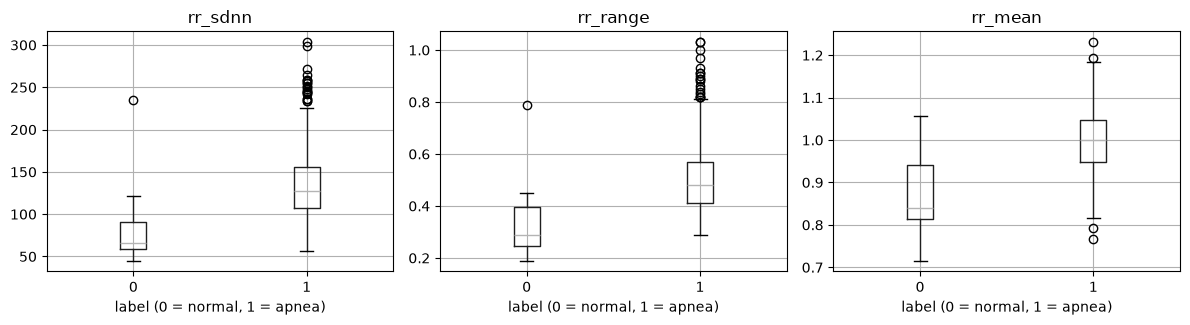

In [ ]:
cols = ["rr_mean", "rr_sdnn", "rr_rmssd", "rr_pnn50", "rr_range", "hr_mean"]
print(df_a01.groupby("label")[cols].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, ["rr_sdnn", "rr_range", "rr_mean"]):
    df_a01.boxplot(column=c, by="label", ax=ax)
    ax.set_title(c); ax.set_xlabel("label (0 = normal, 1 = apnea)")
plt.suptitle(""); plt.tight_layout(); plt.show()